In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import json

# Preprocessing

### Load the Dataset

In [3]:
# Load the dataset
data = pd.read_csv('/content/drive/MyDrive/FYP-I/Combined_Dataset.csv')

# Preview the dataset
print(data.shape)

(99737, 2)


In [4]:
r, _ = np.where(data.isna())
print(r)

[  637  1041  1589  2419  3191  4102  4206  4638  6022  6069  6518  6522
  7528  8839  9977  9977 10172 10438 12840 13337 13425 15346 16416 20375
 20809 22021 22640 23820 24146 24259 27890 29143 31270 33032 33496 33542
 35296 36330 39629 39671 42746 45273 45674 45833 47073 47935 48497 49937
 51585 52064 52812 53530 53855 53855 54255 55070 56360 61897 62054 62425
 63180 63569 64707 65156 65201 65639 66980 67769 68199 68547 70046 70083
 71083 71116 71125 71621 71793 73939 73958 74150 74391 76987 77703 78083
 78216 78999 81380 81765 84529 85475 86343 86817 87292 88203 89019 89343
 91179 91368 94952 95131 98896 99629]


In [5]:
data = data.dropna()
data.shape

(99637, 2)

In [6]:
print(data['type'].unique())

['fake' 'real' 'false' 'mostly-false' 'half-true' 'true' 'pants-fire'
 'mostly-true' 'barely-true' 'political' 'conspiracy' 'reliable' 'unknown'
 'unreliable' 'bias' 'clickbait' 'junksci' 'hate']


### Text Standardization

In [7]:
import re

def standardize_text(text):
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'[^a-z\s]', '', text)  # Remove non-alphanumeric characters
    return text

# data = data.dropna()
print(data.shape)
data['content'] = data['content'].apply(standardize_text)
print(data.shape)

(99637, 2)
(99637, 2)


### Tokenization

In [8]:
import nltk
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

from nltk.tokenize import word_tokenize

nltk.download('punkt')

data['tokens'] = data['content'].apply(word_tokenize)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


### Stop Word Removal

In [ ]:
from nltk.corpus import stopwords

nltk.download('stopwords')


In [ ]:
stop_words = set(stopwords.words('english'))

def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop_words]

data['tokens'] = data['tokens'].apply(remove_stopwords)

Pattern Filtering with RegEx

In [ ]:
def filter_patterns(text):
    text = re.sub(r'\b\d+\b', '', text)  # Remove numbers
    text = re.sub(r'http\S+|www\S+|@\S+', '', text)  # Remove URLs and emails
    return text

data['content'] = data['content'].apply(filter_patterns)

### Duplicate Removal

In [ ]:
data.drop_duplicates(subset='content', inplace=True)
print(data.shape)

### Lemmatization

In [ ]:
import spacy

nlp = spacy.load('en_core_web_sm')

def lemmatize_text(tokens):
    doc = nlp(' '.join(tokens))
    return [token.lemma_ for token in doc]

data['tokens'] = data['tokens'].apply(lemmatize_text)

### Combine Tokens Back to Text

In [ ]:
data['preprocessed_content'] = data['tokens'].apply(lambda tokens: ' '.join(tokens))

### Save the Preprocessed Dataset

In [ ]:
data.to_csv('/content/drive/MyDrive/FYP-I/Sentence_Embeddings-Final-3.csv', index=False)

# **Embeddings** **Generation**

### Install FastText

In [9]:
!pip install fasttext


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 4.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-2.13.6-py3-none-any.whl.metadata (9.5 kB)
Using cached pybind11-2.13.6-py3-none-any.whl (243 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp311-cp311-linux_x86_64.whl size=4313475 sha256=e28f7cb08d7faa7e50160b7089a177a3069652ea24a16e50939224e68fb7d865
  Stored in directory: /root/.cache/pip/wheels/65/4f/35/5057db0249224e9ab55a513fa6b79451473ceb7713017823c3
Successfully built fasttext


### Unsupervised FastText Embedding Generation

Prepare the Training Data

In [ ]:
# Save content column as a plain text file
with open('unsupervised_training.txt', 'w', encoding='utf-8') as f:
    for content in data['preprocessed_content']:
        f.write(content + '\n')


Train the Unsupervised FastText Model

In [ ]:
import fasttext

# Train an unsupervised FastText model
unsupervised_model = fasttext.train_unsupervised('/content/drive/MyDrive/FYP-I/unsupervised_training.txt', model='skipgram', dim=128)

# Save the model
unsupervised_model.save_model('/content/drive/MyDrive/FYP-I/unsupervised_fasttext_model.bin')


In [ ]:
# Save the model
unsupervised_model.save_model('/content/drive/MyDrive/FYP-I/unsupervised_fasttext_model.bin')

### Determine Sentence Length

In [11]:
import pandas as pd

# Read the text file into a DataFrame
data7 = pd.read_csv('/content/drive/MyDrive/FYP-I/Preprocessed_Dataset-4.csv')

# Preview the DataFrame
print(data7.head())
print(data7.shape)

    type                                            content  \
0   fake   shia labeouf maniacally screams he will not d...   
1   real  reuters  us health insurer anthem inc antmn sa...   
2   fake                     anne heche and ellen degeneres   
3  false  melania dug up the wh rose garden removing ros...   
4   fake  republicans in hawaii punished the first femal...   

                                              tokens  \
0  ['shia', 'labeouf', 'maniacally', 'scream', 'd...   
1  ['reuter', 'us', 'health', 'insurer', 'anthem'...   
2             ['anne', 'heche', 'ellen', 'degenere']   
3  ['melania', 'dug', 'wh', 'rise', 'garden', 're...   
4  ['republicans', 'hawaii', 'punish', 'first', '...   

                                preprocessed_content  
0  shia labeouf maniacally scream divide we trump...  
1  reuter us health insurer anthem inc antmn say ...  
2                          anne heche ellen degenere  
3  melania dug wh rise garden remove rose every f...  
4  republ

In [12]:
data7['preprocessed_content']
df1 = data7[data7.isna().any(axis=1)]
print(df1['preprocessed_content'])
print(df1['content'])
data7 = data7.dropna(subset = ['preprocessed_content'])
print(data7.shape)

420                                   NaN
1125     httpswwwyoutubecomwatchvwydxnlow
6763                                  NaN
28926                                 NaN
71044                                 NaN
80383                                 NaN
84736                                 NaN
Name: preprocessed_content, dtype: object
420                       
1125                   NaN
6763                      
28926    what up with that
71044                     
80383            on and on
84736         i ve had it 
Name: content, dtype: object
(91647, 4)


In [25]:
# Tokenize sentences into words to calculate lengths
data7['sentence_length'] = data7['preprocessed_content'].apply(lambda x: len(x.split()))

# Calculate average and most frequent sentence length
avg_length = int(data7['sentence_length'].mean())
freq_length = data7['sentence_length'].mode()[0]

print(f"Average Sentence Length: {avg_length}")
print(f"Most Frequent Sentence Length: {freq_length}")


Average Sentence Length: 106
Most Frequent Sentence Length: 8


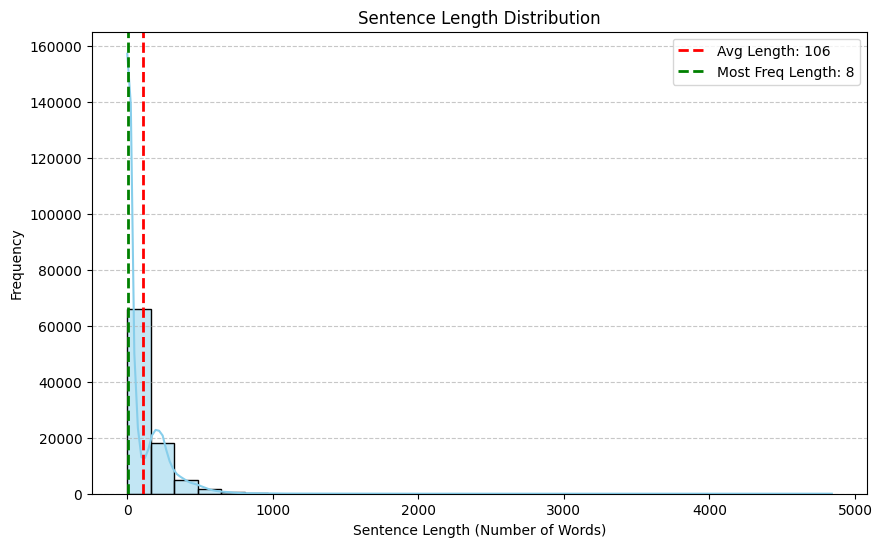

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns


# Plot sentence length distribution
plt.figure(figsize=(10, 6))
sns.histplot(data7['sentence_length'], bins=30, kde=True, color="skyblue", edgecolor="black")
plt.axvline(avg_length, color='red', linestyle='dashed', linewidth=2, label=f'Avg Length: {avg_length}')
plt.axvline(freq_length, color='green', linestyle='dashed', linewidth=2, label=f'Most Freq Length: {freq_length}')
plt.xlabel("Sentence Length (Number of Words)")
plt.ylabel("Frequency")
plt.title("Sentence Length Distribution")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()




In [23]:
# Count occurrences of each sentence length
length_counts = data7['sentence_length'].value_counts().sort_index()

# Display all lengths and their corresponding frequencies
print("\nSentence Length Frequencies:")
for length, count in length_counts.items():
    print(f"Length: {length}, Frequency: {count}")


Sentence Length Frequencies:
Length: 1, Frequency: 60
Length: 2, Frequency: 561
Length: 3, Frequency: 640
Length: 4, Frequency: 1349
Length: 5, Frequency: 2285
Length: 6, Frequency: 3887
Length: 7, Frequency: 5232
Length: 8, Frequency: 5916
Length: 9, Frequency: 5549
Length: 10, Frequency: 4675
Length: 11, Frequency: 3577
Length: 12, Frequency: 2797
Length: 13, Frequency: 1960
Length: 14, Frequency: 1399
Length: 15, Frequency: 1108
Length: 16, Frequency: 922
Length: 17, Frequency: 745
Length: 18, Frequency: 606
Length: 19, Frequency: 561
Length: 20, Frequency: 452
Length: 21, Frequency: 367
Length: 22, Frequency: 332
Length: 23, Frequency: 358
Length: 24, Frequency: 326
Length: 25, Frequency: 297
Length: 26, Frequency: 321
Length: 27, Frequency: 289
Length: 28, Frequency: 282
Length: 29, Frequency: 307
Length: 30, Frequency: 277
Length: 31, Frequency: 272
Length: 32, Frequency: 286
Length: 33, Frequency: 312
Length: 34, Frequency: 313
Length: 35, Frequency: 325
Length: 36, Frequency: 

In [14]:
# Calculate character length of each sentence
data7['char_length'] = data7['preprocessed_content'].apply(lambda x: len(x))

# Calculate average and most frequent character length
avg_char_length = int(data7['char_length'].mean())  # Average character length
freq_char_length = data7['char_length'].mode()[0]   # Most frequent character length

print(f"Average Sentence Character Length: {avg_char_length}")
print(f"Most Frequent Sentence Character Length: {freq_char_length}")

# Choose one (e.g., average length)
max_char_length = avg_char_length  # Or use freq_char_length


Average Sentence Character Length: 759
Most Frequent Sentence Character Length: 54


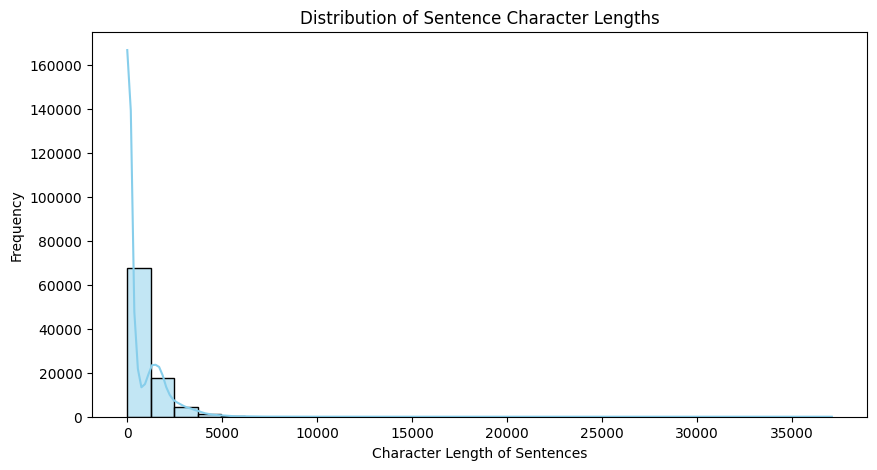

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot histogram of character lengths
plt.figure(figsize=(10, 5))
sns.histplot(data7['char_length'], bins=30, kde=True, color='skyblue')

# Labels and title
plt.xlabel("Character Length of Sentences")
plt.ylabel("Frequency")
plt.title("Distribution of Sentence Character Lengths")

# Show the plot
plt.show()


In [ ]:
# Define the threshold length
threshold_length = 1000  # Change this value as needed

# Count sentences with character length less than the threshold
num_sentences_below_threshold = (data7['char_length'] < threshold_length).sum()

# Print the result
print(f"Number of sentences with character length less than {threshold_length}: {num_sentences_below_threshold}")


## Generate Sentence-Level Embeddings

In [ ]:
import numpy as np

import fasttext

# Load the trained FastText model
model = fasttext.load_model('/content/drive/MyDrive/FYP-I/unsupervised_fasttext_model.bin')

# Function to create sentence-level embeddings
def generate_sentence_embedding(text, model, max_length):
    words = text.split()
    # Trim or pad the words to the desired length
    if len(words) > max_length:
        words = words[:max_length]  # Truncate
    else:
        words.extend([''] * (max_length - len(words)))  # Pad with empty strings

    # Generate word embeddings and average them
    vectors = [model.get_word_vector(word) for word in words if word in model.words]
    return np.mean(vectors, axis=0) if vectors else np.zeros(128)

# Apply embedding generation to all sentences
data7.shape
data7['sentence_embedding'] = data7['preprocessed_content'].apply(lambda x: generate_sentence_embedding(x, model, max_length))


In [ ]:
data7.shape

In [ ]:
import numpy as np
import fasttext

max_length = 120  # Maximum word length in any input text
embedding_dim = 128  # Each word embedding dimension

# Load the trained FastText model
model = fasttext.load_model('/content/drive/MyDrive/FYP-I/unsupervised_fasttext_model.bin')

# Function to create sentence-level embeddings
def generate_sentence_embedding(text, model, max_length, embedding_dim):
    words = text.split()

    # Trim or pad words to max_length
    if len(words) > max_length:
        words = words[:max_length]  # Truncate
    else:
        words.extend([''] * (max_length - len(words)))  # Pad with empty strings

    # Generate word embeddings for each word
    vectors = [model.get_word_vector(word) for word in words if word in model.words]

    # Convert to NumPy array
    if vectors:
        sentence_embedding = np.vstack(vectors)  # Stack word embeddings (shape: num_words × embedding_dim)
    else:
        sentence_embedding = np.zeros((max_length, embedding_dim))  # If no words, return zero matrix

    # Ensure final shape is (120, 128), padding if needed
    if sentence_embedding.shape[0] < max_length:
        padding = np.zeros((max_length - sentence_embedding.shape[0], embedding_dim))
        sentence_embedding = np.vstack([sentence_embedding, padding])

    return sentence_embedding  # Shape: (120, 128)

# Apply embedding generation to all sentences
data7['sentence_embedding_2'] = data7['preprocessed_content'].apply(
    lambda x: generate_sentence_embedding(x, model, max_length, embedding_dim)
)



Batch

In [ ]:
import numpy as np
import fasttext
import pandas as pd

max_length = 120
embedding_dim = 128
batch_size = 1000  # Adjust based on memory constraints

# Load the FastText model
model = fasttext.load_model('/content/drive/MyDrive/FYP-I/unsupervised_fasttext_model.bin')

# Function to generate sentence embeddings (row-wise processing)
def generate_sentence_embedding(text, model, max_length, embedding_dim):
    words = text.split()
    words = words[:max_length] if len(words) > max_length else words + [''] * (max_length - len(words))

    # Generate embeddings and stack them into (max_length, embedding_dim)
    vectors = [model.get_word_vector(word) for word in words if word in model.words]

    if vectors:
        sentence_embedding = np.vstack(vectors)
    else:
        sentence_embedding = np.zeros((max_length, embedding_dim))

    # Pad if needed
    if sentence_embedding.shape[0] < max_length:
        padding = np.zeros((max_length - sentence_embedding.shape[0], embedding_dim))
        sentence_embedding = np.vstack([sentence_embedding, padding])

    return sentence_embedding.astype(np.float16)  # Reduce memory usage

In [ ]:
def process_in_batches(df, batch_size, model, max_length, embedding_dim):
    total_batches = len(df) // batch_size + 1
    embeddings_list = []

    for i in range(total_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, len(df))
        batch = df.iloc[start_idx:end_idx]

        print(f"Processing batch {i+1}/{total_batches}...")

        batch_embeddings = batch['preprocessed_content'].apply(
            lambda x: generate_sentence_embedding(x, model, max_length, embedding_dim)
        )

        embeddings_list.extend(batch_embeddings)

    return embeddings_list

In [ ]:
# Process the dataset in batches
data7['sentence_embedding_2'] = process_in_batches(data7, batch_size, model, max_length, embedding_dim)

Positional Embeddings

In [ ]:
import numpy as np
import pandas as pd

# **Set Parameters**
max_length = 120  # Maximum words in a sentence
embedding_dim = 128  # Dimensionality of embeddings
batch_size = 1000  # Batch size to optimize memory usage

# 📌 **Function to generate sinusoidal positional encodings**
def generate_positional_encoding(max_length, embedding_dim):
    """
    Generates sinusoidal positional encodings.
    """
    position = np.arange(max_length)[:, np.newaxis]
    div_term = np.exp(np.arange(0, embedding_dim, 2) * -(np.log(10000.0) / embedding_dim))

    pos_encoding = np.zeros((max_length, embedding_dim))
    pos_encoding[:, 0::2] = np.sin(position * div_term)  # Apply sine to even indices
    pos_encoding[:, 1::2] = np.cos(position * div_term)  # Apply cosine to odd indices

    return pos_encoding.astype(np.float16)  # Reduce memory usage

# **Precompute Positional Encoding for all positions**
positional_encoding = generate_positional_encoding(max_length, embedding_dim)

# 📌 **Function to generate positional encoding for a given sentence**
def generate_sentence_positional_encoding(text, max_length, embedding_dim):
    words = text.split()

    # **Truncate or Pad**
    words = words[:max_length] if len(words) > max_length else words + [''] * (max_length - len(words))

    # **Get Positional Encoding for sentence length**
    return positional_encoding[:len(words)].astype(np.float16)

# 📌 **Function to process positional encodings in batches**
def process_positional_encodings(df, batch_size, max_length, embedding_dim):
    total_batches = len(df) // batch_size + 1
    encodings_list = []

    for i in range(total_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, len(df))
        batch = df.iloc[start_idx:end_idx]

        print(f"Processing batch {i+1}/{total_batches}...")

        batch_encodings = batch['preprocessed_content'].apply(
            lambda x: generate_sentence_positional_encoding(x, max_length, embedding_dim)
        )

        encodings_list.extend(batch_encodings)

    return encodings_list


In [ ]:
# Process positional encodings in batches
positional_encodings = process_positional_encodings(data7, batch_size, max_length, embedding_dim)

# Convert to NumPy array
positional_encodings = np.array(positional_encodings)


In [ ]:
# **Save as .npy file**
np.save('/content/drive/MyDrive/FYP-I/positional_encodings-Final.npy', positional_encodings)

# **Character Embeddings**

In [ ]:
import numpy as np
import fasttext
import pandas as pd

max_chars = 2000  # Maximum character length of a sentence
embedding_dim = 128
batch_size = 10  # Adjust based on memory constraints

# Load the FastText model
model = fasttext.load_model('/content/drive/MyDrive/FYP-I/unsupervised_fasttext_model.bin')

# Function to generate character-level embeddings
def generate_char_embedding(text, model, max_chars, embedding_dim):
    chars = list(text)  # Split sentence into characters
    chars = chars[:max_chars] if len(chars) > max_chars else chars + [' '] * (max_chars - len(chars))  # Truncate or pad

    # Generate embeddings for each character
    vectors = [model.get_word_vector(char) if char in model.words else np.zeros(embedding_dim) for char in chars]

    # Stack into (max_chars, embedding_dim)
    sentence_embedding = np.vstack(vectors)

    return sentence_embedding.astype(np.float16)  # Reduce memory usage

In [ ]:
# Function to process dataset in batches
def process_in_batches(df, batch_size, model, max_chars, embedding_dim):
    total_batches = len(df) // batch_size + 1
    embeddings_list = []

    for i in range(total_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, len(df))
        batch = df.iloc[start_idx:end_idx]

        print(f"Processing batch {i+1}/{total_batches}...")

        batch_embeddings = batch['preprocessed_content'].apply(
            lambda x: generate_char_embedding(x, model, max_chars, embedding_dim)
        )

        embeddings_list.extend(batch_embeddings)

    return embeddings_list

In [ ]:
# Process dataset in batches
data7['char_level_embedding_2'] = process_in_batches(data7, batch_size, model, max_chars, embedding_dim)

# **Process in batches character**

In [ ]:
import numpy as np
import fasttext
import pandas as pd
import os

# Constants
MAX_CHARS = 2000  # Max character length per sentence
EMBEDDING_DIM = 128
BATCH_SIZE = 1000  # Adjust based on Colab memory
SAVE_PATH = '/content/drive/MyDrive/FYP-I/char_level_embeddings_2.npy'  # Save file path

# Load FastText model
model = fasttext.load_model('/content/drive/MyDrive/FYP-I/unsupervised_fasttext_model.bin')

In [ ]:
def generate_char_embedding(text, model, max_chars, embedding_dim):
    """
    Generate character-level embeddings for a given text.
    Returns a (max_chars, embedding_dim) matrix.
    """
    chars = list(text)
    chars = chars[:max_chars] if len(chars) > max_chars else chars + [' '] * (max_chars - len(chars))

    vectors = [model.get_word_vector(char) if char in model.words else np.zeros(embedding_dim) for char in chars]

    return np.vstack(vectors).astype(np.float16)

In [ ]:
def check_existing_progress(save_path, batch_size):
    """
    Checks if an existing embedding file is available.
    If yes, returns the starting batch index and existing embeddings.
    """
    if os.path.exists(save_path):
        existing_embeddings = np.load(save_path, allow_pickle=True)
        existing_embeddings = existing_embeddings.tolist()  # Convert to list to append more data
        start_batch = len(existing_embeddings) // batch_size
        print(f"Resuming from batch {start_batch + 1}...")
    else:
        existing_embeddings = []
        start_batch = 0
    return start_batch, existing_embeddings

In [ ]:
def process_in_batches(df, batch_size, model, max_chars, embedding_dim, save_path):
    """
    Processes the dataset in batches and saves embeddings incrementally.
    """
    start_batch, existing_embeddings = check_existing_progress(save_path, batch_size)
    total_batches = len(df) // batch_size + 1

    for i in range(start_batch, total_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, len(df))
        batch = df.iloc[start_idx:end_idx]

        print(f"Processing batch {i+1}/{total_batches}...")

        batch_embeddings = batch['preprocessed_content'].apply(
            lambda x: generate_char_embedding(x, model, max_chars, embedding_dim)
        ).tolist()

        # existing_embeddings.extend(batch_embeddings)
        # existing_embeddings += batch_embeddings
        if existing_embeddings:
            existing_embeddings.extend(batch_embeddings)  # Append new batch embeddings
        else:
            existing_embeddings = batch_embeddings  # Initialize if empty

        # Save after each batch
        np.save(save_path, np.array(existing_embeddings, dtype=np.float16))
        print(f"✅ Saved progress after batch {i+1}.")

    print("🎉 All batches processed and saved successfully.")

In [ ]:
# Call the function on data7
process_in_batches(data7, BATCH_SIZE, model, MAX_CHARS, EMBEDDING_DIM, SAVE_PATH)

In [ ]:
# Save embeddings to a file
np.save('/content/drive/MyDrive/FYP-I/char_level_embeddings.npy', np.stack(data7['char_level_embedding'].values))

# Merge

In [ ]:
import os
import numpy as np

SAVE_DIR = '/content/drive/MyDrive/FYP-I/char_level_batches/'  # Directory containing batche

MERGED_PATH = '/content/drive/MyDrive/FYP-I/char_level_embeddings-128.npy'  # Final file

# Load and merge all batches
all_embeddings = []
for file in sorted(os.listdir(SAVE_DIR), key=lambda x: int(x.split('_')[-1].split('.npy')[0])):
    batch_embeddings = np.load(os.path.join(SAVE_DIR, file))
    all_embeddings.append(batch_embeddings)

# Stack all batches into one array and save
final_embeddings = np.vstack(all_embeddings)
np.save(MERGED_PATH, final_embeddings)
print(f"✅ Merged all batches and saved to {MERGED_PATH}")


In [ ]:
# Load the merged embeddings (batch-wise reading)
final_embeddings = []
with open(MERGED_PATH, 'rb') as f_in:
    while True:
        try:
            batch = np.load(f_in)
            final_embeddings.append(batch)
        except EOFError:
            break  # Stop when file ends

# Convert to single array if needed
final_embeddings = np.vstack(final_embeddings)
print("✅ Loaded final embeddings with shape:", final_embeddings.shape)


# **One single batch file:**

In [ ]:
import os
import numpy as np

SAVE_DIR = '/content/drive/MyDrive/FYP-I/char_level_batches/'  # Directory containing batch embeddings
FINAL_PATH = '/content/drive/MyDrive/FYP-I/char_level_embeddings_final-128.npy'  # Single output file

batch_files = sorted(os.listdir(SAVE_DIR), key=lambda x: int(x.split('_')[-1].split('.npy')[0]))

# Load batches incrementally and merge efficiently
final_embeddings = []
for i, file in enumerate(batch_files):
    batch_path = os.path.join(SAVE_DIR, file)
    batch_embeddings = np.load(batch_path)
    final_embeddings.append(batch_embeddings)

    print(f"✅ Loaded batch {i+1}/{len(batch_files)}: {batch_path}")

# Convert list of batches into a single NumPy array
final_embeddings = np.vstack(final_embeddings)

# Save the complete array as a single `.npy` file
np.save(FINAL_PATH, final_embeddings)

print(f"\n🎉 All embeddings merged & saved in ONE file: {FINAL_PATH}")
print(f"Final shape of saved embeddings: {final_embeddings.shape}")


# **final char embeddings in a single df**

In [ ]:
import os
import numpy as np
import pandas as pd

SAVE_DIR = '/content/drive/MyDrive/FYP-I/char_level_batches/'  # Directory containing batch embeddings
batch_files = sorted(os.listdir(SAVE_DIR), key=lambda x: int(x.split('_')[-1].split('.npy')[0]))

# Load all batches and merge
all_embeddings = []
for i, file in enumerate(batch_files):
    batch_path = os.path.join(SAVE_DIR, file)
    batch_embeddings = np.load(batch_path)
    all_embeddings.append(batch_embeddings)
    print(f"✅ Loaded batch {i+1}/{len(batch_files)}: {batch_path}")

# Convert to single NumPy array
final_embeddings = np.vstack(all_embeddings)  # Shape: (85878, 2000, 128)

# Convert to Pandas DataFrame
df_embeddings = pd.DataFrame({'embedding': list(final_embeddings)})

# Print shape for verification
print(f"\n🎉 DataFrame shape: {df_embeddings.shape}")  # Expected: (85878, 1)
print(f"✅ Each entry is an array of shape {df_embeddings['embedding'][0].shape}")  # Expected: (2000, 128)


In [ ]:
# Process the dataset in batches
data7['sentence_embedding_2'] = process_in_batches(data7, batch_size, model, max_length, embedding_dim)

In [ ]:
import numpy as np

# Convert the list of embeddings to a NumPy array
embeddings_array = np.array(data7['sentence_embedding_2'].tolist())  # Shape: (num_samples, 120, 128)

# Save to `.npy` file (Best for fast loading)
np.save('/content/drive/MyDrive/FYP-I/sentence_embeddings-final-120-128.npy', embeddings_array)


In [ ]:
import pandas as pd

# Flatten each (120, 128) matrix into a (1, 120*128) vector
flattened_embeddings = data7['sentence_embedding_2'].apply(lambda x: x.flatten())

# Convert to DataFrame
embedding_df = pd.DataFrame(flattened_embeddings.tolist())

# Save as CSV
embedding_df.to_csv('/content/drive/MyDrive/FYP-I/sentence_embeddings-final-120-128.csv', index=False)


## Save the Sentence Embeddings

In [ ]:
# Save embeddings to a file (e.g., NumPy format)
np.save('/content/drive/MyDrive/FYP-I/sentence_embeddings-4.npy', np.vstack(data7['sentence_embedding'].values))

# Alternatively, save as a CSV file
embedding_df = pd.DataFrame(data7['sentence_embedding'].tolist())
embedding_df.to_csv('/content/drive/MyDrive/FYP-I/sentence_embeddings-final-4.csv', index=False)


In [ ]:
data7.to_csv('/content/drive/MyDrive/FYP-I/Preprocessed_Dataset-Final.csv', index=False)

In [ ]:
data9 = pd.read_csv('/content/drive/MyDrive/FYP-I/Preprocessed_Dataset-Final.csv')

# Preview the DataFrame
print(data9.shape)

## Standardize labels

In [10]:
vc = data['type'].value_counts()
print(vc)

type
real            38858
fake            29391
false            7598
half-true        5692
mostly-true      5286
true             4127
pants-fire       3533
mostly-false     3432
barely-true      1637
conspiracy         31
political          23
unknown             6
unreliable          6
bias                6
junksci             6
reliable            3
clickbait           1
hate                1
Name: count, dtype: int64


In [ ]:
data8 = data8[data8['type'] != 'hate']
# print(data8.shape)
data8 = data8[data8['type'] != 'clickbait']
# print(data8.shape)
data8 = data8[data8['type'] != 'reliable']
# print(data8.shape)
data8 = data8[data8['type'] != 'junksci']
# print(data8.shape)
data8 = data8[data8['type'] != 'bias']
# print(data8.shape)
data8 = data8[data8['type'] != 'unreliable']
# print(data8.shape)
data8 = data8[data8['type'] != 'unknown']
# print(data8.shape)
data8 = data8[data8['type'] != 'political']
# print(data8.shape)
data8 = data8[data8['type'] != 'conspiracy']
# print(data8.shape)
data8 = data8[data8['type'] != 'half-true']
print(data8.shape)

In [ ]:
data8['type'].replace('false', 'fake', inplace=True)
vc = data8['type'].value_counts()

data8['type'].replace('true', 'real', inplace=True)
vc = data8['type'].value_counts()

data8['type'].replace('pants-fire', 'fake', inplace=True)
vc = data8['type'].value_counts()

data8['type'].replace('barely-true', 'fake', inplace=True)
vc = data8['type'].value_counts()

data8['type'].replace('mostly-false', 'fake', inplace=True)
vc = data8['type'].value_counts()

data8['type'].replace('mostly-true', 'real', inplace=True)
vc = data8['type'].value_counts()
print(vc)
print(data8.shape)

In [ ]:
# data8.index.values.tolist()
data8.to_csv('/content/drive/MyDrive/FYP-I/Preprocessed_Dataset-Final-2.csv', index=False)

Dataloader Generation

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd


In [ ]:
class FakeNewsDataset(Dataset):
    def __init__(self, embeddings_file, labels_file=None):
        """
        Initialize the dataset with embeddings and optionally labels.
        :param embeddings_file: Path to the CSV file containing fixed embeddings.
        :param labels_file: Path to the CSV file containing labels (optional for inference).
        """
        # Load embeddings
        self.embeddings = pd.read_csv(embeddings_file, header=None).values

        # Load labels (if provided)
        if labels_file:
            # Read labels and convert them to integers, ensuring they're numeric and valid
            self.labels = pd.read_csv(labels_file, header=None)[0]
            # print(labels[0].type)

            # Ensure labels are either '0' or '1' and convert them to integers
            # self.labels = labels.apply(lambda x: int(x) if x in ['0', '1'] else 0).values
            # print(labels)
        else:
            self.labels = None

    def __len__(self):
        """Return the number of samples."""
        return len(self.embeddings)

    def __getitem__(self, idx):
        """
        Retrieve a single sample (embedding, label).
        :param idx: Index of the sample.
        """
        embedding = torch.tensor(self.embeddings[idx], dtype=torch.float32)

        if self.labels is not None:
            label = torch.tensor(self.labels[idx], dtype=torch.long)
            return embedding, label
        else:
            return embedding


Create the DataLoader

In [ ]:
# Path to the embeddings and labels
embeddings_file = '/content/drive/MyDrive/FYP-I/fixed_embeddings.csv'
labels_file = '/content/drive/MyDrive/FYP-I/encoded_labels.csv'  # CSV file with a 'type' column for real/fake labels

# Initialize the dataset with both embeddings and labels
dataset = FakeNewsDataset(embeddings_file, labels_file)


In [ ]:
train_dataset, val_dataset, test_dataset = split_dataset(dataset, train_ratio=0.8, val_ratio=0.1)

# Create DataLoaders for each subset
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)

# Example: Iterate through train DataLoader
for embeddings, labels in train_loader:
    print("Train batch:", embeddings.shape, labels.shape)
    break

# Example: Iterate through validation DataLoader
for embeddings, labels in val_loader:
    print("Validation batch:", embeddings.shape, labels.shape)
    break

# Example: Iterate through test DataLoader
for embeddings, labels in test_loader:
    print("Test batch:", embeddings.shape, labels.shape)
    break